# 05 · Interactive demo: "what could this place look like after a disaster?"

1. Search for a place or pan the map, then draw a **rectangle** (≤ 25 km², inside Kerala).
2. Choose the model (pix2pix or diffusion), the hazard and a rainfall scenario, then press
   **Generate**.
3. Press ▶ to crossfade from today's image (severity 0) to increasingly severe outcomes.

Generated images are plausible scenarios for hazard communication, **not predictions**.
Severities above the range seen in training are marked as extrapolation.
**How to run:** Runtime → Run all. Works in any Google account: the trained models and the
test tiles are downloaded from shared links, no Google Drive needed. Runtime: GPU recommended.

The saved examples always run. The live map also needs Earth Engine: sign in when asked; if
that account cannot use `GEE_PROJECT`, the map is skipped with a message (examples still run).

In [1]:
from google.colab import output

GEE_PROJECT = "practical-range-495917-q8"  # your Earth Engine Cloud project
REPO_URL = "https://github.com/muhammedshahidsds25-collab/kerala-hazard-vision-ai.git"
REPO_DIR = "/content/kerala-hazard-vision-ai"
# Shared Google Drive folders ("Anyone with the link") holding the two trained models.
GAN_FOLDER_URL = "https://drive.google.com/drive/folders/1nr4aG_OQme16UpHARmxtpOm__y6qRID3"
DIFFUSION_FOLDER_URL = "https://drive.google.com/drive/folders/1yBvYIRXWNecgHBQ7v-KDFZnLq_Et-n_I"
TILES_URL = "https://drive.google.com/file/d/1WC1wOosic5MNSI44HxkPHnxxwbgibxtZ/view?usp=sharing"

output.enable_custom_widget_manager()  # needed for the map widget in Colab
!git clone -q {REPO_URL} {REPO_DIR} || git -C {REPO_DIR} pull -q
%cd {REPO_DIR}
# Regular (not editable) install: an editable src-layout install is not importable
# until the runtime restarts.
!pip install -q ".[gee]" gdown

/content/kerala-hazard-vision-ai
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import io
import zipfile
from pathlib import Path

import ee
import gdown
import geemap
import ipywidgets as widgets
import numpy as np
import torch
from PIL import Image

from kerala_hazard_vision_ai.config import load_config
from kerala_hazard_vision_ai.data.dataset import list_tiles, load_shared_stats
from kerala_hazard_vision_ai.data.severity import HAZARD_CODES
from kerala_hazard_vision_ai.demo import (
    crossfade,
    fetch_area,
    generate_sweep,
    is_extrapolation,
    rain_plane_cond,
)
from kerala_hazard_vision_ai.evaluate import (
    HAZARD_NAMES,
    diffusion_predict,
    gan_predict,
    plot_severity_sweep,
    rgb_uint8,
)
from kerala_hazard_vision_ai.models import load_generator
from kerala_hazard_vision_ai.train_diffusion import load_diffusion

try:  # Earth Engine is only needed for the live map
    ee.Authenticate()
    ee.Initialize(project=GEE_PROJECT)
    EE_OK = True
except Exception as error:
    EE_OK = False
    print(f"Earth Engine unavailable, the live map will be skipped: {error}")
cfg = load_config("configs/default.yaml")
FIG_DIR = Path("/content/outputs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

GAN_DIR, DIFFUSION_DIR = Path("/content/checkpoints"), Path("/content/checkpoints_diffusion")
for url, folder in ((GAN_FOLDER_URL, GAN_DIR), (DIFFUSION_FOLDER_URL, DIFFUSION_DIR)):
    if not (folder / "stats.json").exists():  # skip on re-runs
        gdown.download_folder(url, output=str(folder), quiet=True)
stats = load_shared_stats(GAN_DIR, DIFFUSION_DIR)

# Test tiles of the held-out events, for the saved examples (no Earth Engine needed).
TILE_DIR = Path("/content/tiles")
if not TILE_DIR.exists():
    gdown.download(TILES_URL, "/content/tiles.zip", fuzzy=True, quiet=True)
    with zipfile.ZipFile("/content/tiles.zip") as archive:
        archive.extractall(TILE_DIR, members=[n for n in archive.namelist()
                                              if n.startswith(cfg.data.test_events)])
PREDICTORS = {
    "pix2pix": gan_predict(load_generator(GAN_DIR / "best_g.pt", cfg.model, device), device),
    "diffusion": diffusion_predict(
        load_diffusion(DIFFUSION_DIR / "best_ema.pt", cfg, device),
        device, cfg.diffusion.sample_steps, cfg.train.seed,
    ),
}
TRAIN_RAIN_MEAN = float(stats.mean[5])  # channel order: 4 bands, slope, rain, soil
CROSSFADE_STEPS = 30
HAZARD_LABELS = {1: "Landslide", 0: "Flood"}

# Offer only hazards the model was trained on (floods failed the go/no-go check).
TRAINED_HAZARDS = {HAZARD_CODES[e.hazard] for e in cfg.events}

Earth Engine unavailable, the live map will be skipped: Caller does not have required permission to use project practical-range-495917-q8. Grant the caller the roles/serviceusage.serviceUsageConsumer role, or a custom role with the serviceusage.services.use permission, by visiting https://console.developers.google.com/iam-admin/iam?project=practical-range-495917-q8 and then retry. Propagation of the new permission may take a few minutes.


## Saved examples: the most damaged tile of each held-out event, both models

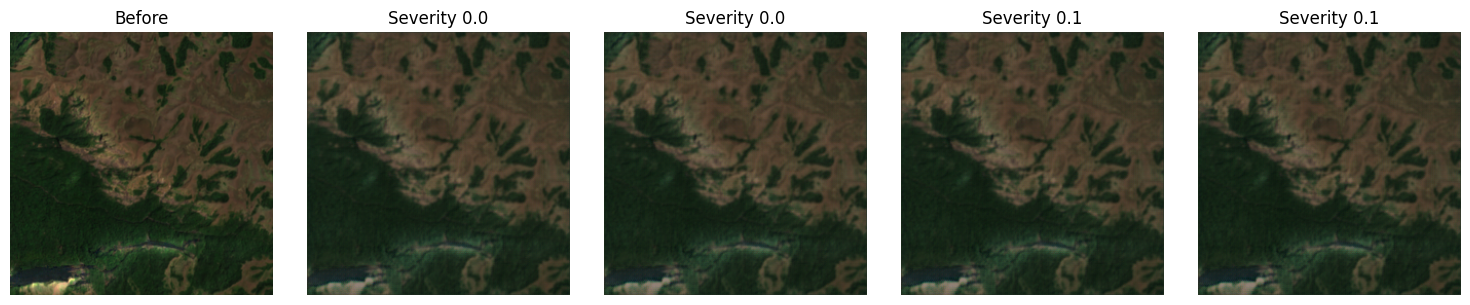

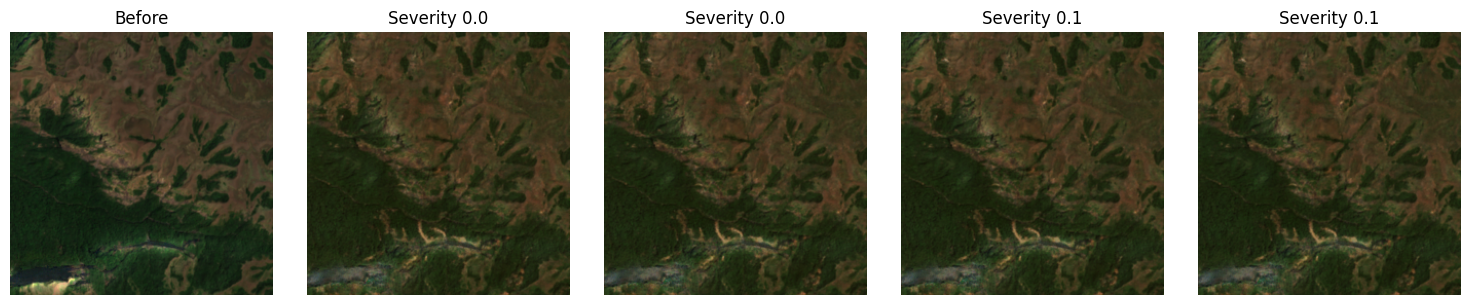

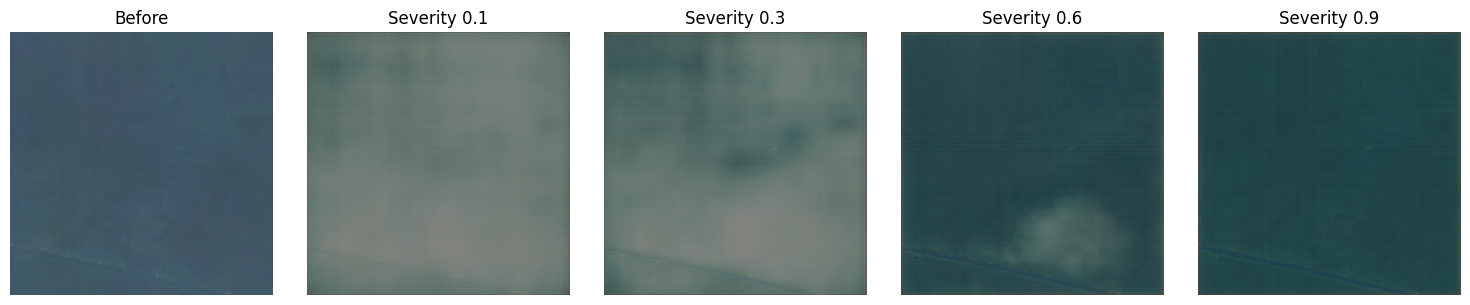

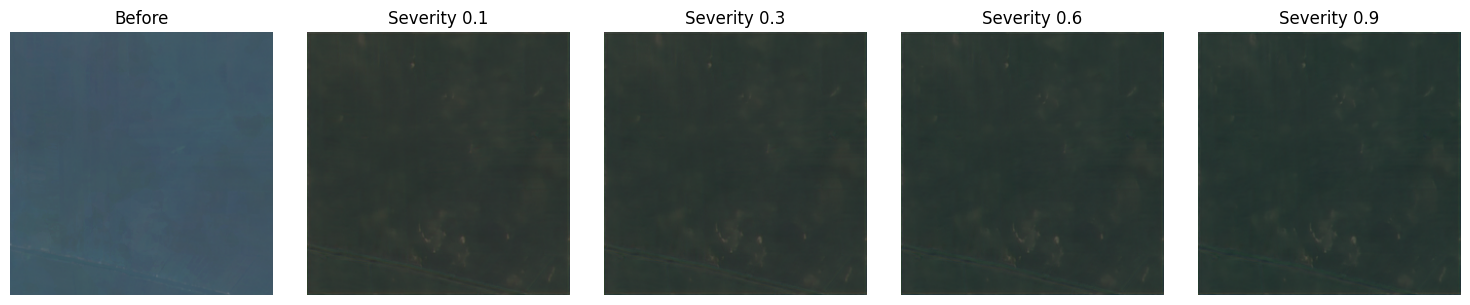

In [3]:
for event_name in cfg.data.test_events:
    tiles = list_tiles(TILE_DIR, [event_name])
    with np.load(max(tiles, key=lambda t: float(np.load(t)["severity"]))) as tile:
        before, cond, hazard_code = tile["before"], tile["cond"], int(tile["hazard"])
    sweep = cfg.demo.sweep[HAZARD_NAMES[hazard_code]]
    today = rgb_uint8(torch.from_numpy(before), cfg.eval.rgb_max)
    for model_name, predict in PREDICTORS.items():
        frames = generate_sweep(predict, before, cond, hazard_code, sweep, stats,
                                cfg.eval.rgb_max, cfg.data.tile_size)
        display(plot_severity_sweep(today, [torch.from_numpy(f).permute(2, 0, 1) for f in frames],
                                    sweep, FIG_DIR / f"demo_{event_name}_{model_name}.png"))

## Live map: draw an area in Kerala

In [4]:
def run_demo(bbox, hazard: int, rain_mm: float, model: str = "pix2pix"):
    """Return (crossfade frames, their severities, today's RGB image, one frame per sweep step)."""
    before, slope, soil = fetch_area(bbox, cfg, HAZARD_NAMES[hazard])
    cond = rain_plane_cond(slope, soil, rain_mm)
    sweep = cfg.demo.sweep[HAZARD_NAMES[hazard]]
    key_frames = generate_sweep(PREDICTORS[model], before, cond, hazard, sweep, stats,
                                cfg.eval.rgb_max, cfg.data.tile_size)
    today = rgb_uint8(torch.from_numpy(before), cfg.eval.rgb_max).permute(1, 2, 0).numpy()
    key_severities = [0.0, *sweep]
    frames = crossfade([today, *key_frames], CROSSFADE_STEPS)
    positions = np.linspace(0, len(key_severities) - 1, CROSSFADE_STEPS)
    severities = np.interp(positions, range(len(key_severities)), key_severities)
    return frames, severities, today, key_frames


def to_png(frame: np.ndarray) -> bytes:
    buffer = io.BytesIO()
    Image.fromarray(frame).save(buffer, format="PNG")
    return buffer.getvalue()


def make_map_ui() -> widgets.VBox:
    # OpenStreetMap blocks tiles requested from Colab, so use Esri satellite imagery instead.
    m = geemap.Map(center=(10.5, 76.5), zoom=8, basemap="Esri.WorldImagery")
    model = widgets.ToggleButtons(
        options=[("pix2pix (fast)", "pix2pix"), ("Diffusion", "diffusion")]
    )
    hazard = widgets.ToggleButtons(
        options=[(HAZARD_LABELS[h], h) for h in sorted(TRAINED_HAZARDS, reverse=True)]
    )
    rain = widgets.FloatSlider(value=TRAIN_RAIN_MEAN, min=0, max=800, step=10,
                               description="Rain (mm/7d)", continuous_update=False)
    generate = widgets.Button(description="Generate", button_style="primary")
    status = widgets.HTML()
    picture = widgets.Image(format="png", width=400)
    play = widgets.Play(min=0, max=CROSSFADE_STEPS - 1, interval=120)
    scrub = widgets.IntSlider(min=0, max=CROSSFADE_STEPS - 1, description="Frame")
    widgets.jslink((play, "value"), (scrub, "value"))
    state = {"frames": [], "severities": []}


    def show(_=None):
        if not state["frames"]:
            return
        i = scrub.value
        picture.value = to_png(state["frames"][i])
        severity = state["severities"][i]
        extrapolated = is_extrapolation(severity, state["hazard"], cfg.demo)
        warning = " ⚠️ <b>extrapolation</b>" if extrapolated else ""
        status.value = f"Severity {severity:.2f}{warning}"


    def on_generate(_):
        if m.user_roi is None:
            status.value = "Draw a rectangle on the map first."
            return
        lons, lats = zip(*m.user_roi.bounds().coordinates().getInfo()[0], strict=True)
        bbox = (min(lons), min(lats), max(lons), max(lats))
        status.value = "Fetching satellite data and generating…"
        try:
            frames, severities, *_ = run_demo(bbox, hazard.value, rain.value, model.value)
            hazard_name = HAZARD_NAMES[hazard.value]
            state.update(frames=frames, severities=severities, hazard=hazard_name)
        except Exception as error:  # show every failure (area, Earth Engine, network) in the UI
            status.value = f"⚠️ {type(error).__name__}: {error}"
            return
        scrub.value = 0
        show()


    generate.on_click(on_generate)
    scrub.observe(show, names="value")
    return widgets.VBox([m, model, widgets.HBox([hazard, rain, generate]),
                         widgets.HBox([play, scrub]), status, picture])


make_map_ui() if EE_OK else print("Live map skipped: Earth Engine is not available here.")

Live map skipped: Earth Engine is not available here.
